In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

In [2]:
# 1. Load Dataset
(x_train, y_train), (x_test, y_test) = \
    tf.keras.datasets.mnist.load_data()
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


In [3]:
# 2. Normalize Data
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0


In [5]:
# 3. Select Normal Data (Digit 0)
normal_class = 0
x_train_normal = x_train[y_train == normal_class]
x_test_normal = x_test[y_test == normal_class]
print("Normal training samples:",
      len(x_train_normal))
print("Normal testing samples:",
      len(x_test_normal))

Normal training samples: 5923
Normal testing samples: 980


In [6]:
# 4. Flatten Images
x_train_normal = x_train_normal.reshape(
    len(x_train_normal), 784
)
x_test_normal = x_test_normal.reshape(
    len(x_test_normal), 784
)


In [7]:
# 5. Build Encoder
input_dim = 784
latent_dim = 32
encoder = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(latent_dim, activation="relu")
])

In [8]:
# 6. Build Decoder
decoder = models.Sequential([
    layers.Input(shape=(latent_dim,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(input_dim, activation="sigmoid")
])

In [9]:
# 7. Combine Encoder + Decoder
autoencoder_input = layers.Input(
    shape=(input_dim,)
)
encoded = encoder(autoencoder_input)
decoded = decoder(encoded)
autoencoder = models.Model(
    autoencoder_input,
    decoded
)


In [10]:
# 8. Compile Model
autoencoder.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
print("\nAutoencoder Summary:")
autoencoder.summary()


Autoencoder Summary:


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# 9. Train Autoencoder
history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    shuffle=True
)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.1161 - mae: 0.2471 - val_loss: 0.0649 - val_mae: 0.1310
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0606 - mae: 0.1306 - val_loss: 0.0523 - val_mae: 0.1202
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0468 - mae: 0.1088 - val_loss: 0.0422 - val_mae: 0.0982
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0415 - mae: 0.0994 - val_loss: 0.0387 - val_mae: 0.0955
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0377 - mae: 0.0934 - val_loss: 0.0346 - val_mae: 0.0870
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0336 - mae: 0.0846 - val_loss: 0.0321 - val_mae: 0.0812
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0307 - mae: 0.0795 - val_loss: 0.0291 - val_mae: 0.0754
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0282 - mae: 0.0742 - val_loss: 0.0273 - val_mae: 0.0724
Epoch 9/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.026

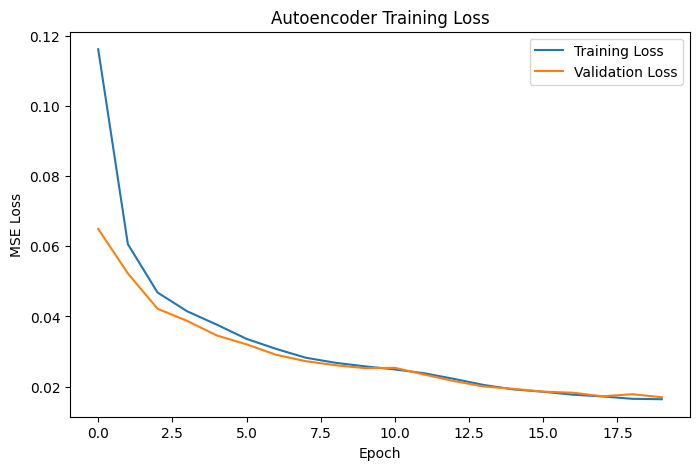

In [12]:
# 10. Plot Training Loss
plt.figure(figsize=(8, 5))
plt.plot(
    history.history["loss"],
    label="Training Loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()

In [13]:
# 11. Reconstruct Normal Data
normal_reconstructed = autoencoder.predict(
    x_test_normal,
    verbose=0
)

In [14]:
# 12. Calculate Normal Reconstruction Error
normal_errors = np.mean(
    np.square(
        x_test_normal - normal_reconstructed
    ),
    axis=1
)

In [15]:
# 13. Calculate Threshold
threshold = np.percentile(
    normal_errors,
    95
)
print("\nAnomaly Threshold:",
      threshold)


Anomaly Threshold: 0.031010969


In [16]:
# 14. Prepare Anomaly Data (Digit 1)
anomaly_class = 1
x_test_anomaly = x_test[
    y_test == anomaly_class
]
x_test_anomaly = x_test_anomaly.reshape(
    len(x_test_anomaly), 784
)
print("Anomaly samples:",
      len(x_test_anomaly))

Anomaly samples: 1135


In [17]:
# 15. Reconstruct Anomaly Data
anomaly_reconstructed = autoencoder.predict(
    x_test_anomaly,
    verbose=0
)

In [18]:
# 16. Calculate Anomaly Error
anomaly_errors = np.mean(
    np.square(
        x_test_anomaly - anomaly_reconstructed
    ),
    axis=1
)

In [19]:
# 17. Detect Anomalies
normal_predictions = normal_errors > threshold
anomaly_predictions = anomaly_errors > threshold

In [20]:
# 18. Calculate Results
normal_false_positive = np.sum(
    normal_predictions
)
anomaly_detected = np.sum(
    anomaly_predictions
)
normal_detection_rate = (
    normal_false_positive /
    len(normal_predictions)
) * 100
anomaly_detection_rate = (
    anomaly_detected /
    len(anomaly_predictions)
) * 100
print("\n========== RESULTS ==========")
print(
    "Normal samples incorrectly classified:",
    normal_false_positive
)
print(
    "Anomalies detected:",
    anomaly_detected
)
print(
    "Anomaly Detection Rate:",
    round(anomaly_detection_rate, 2),
    "%"
)
print(
    "False Positive Rate:",
    round(normal_detection_rate, 2),
    "%"
)


========== RESULTS ==========
Normal samples incorrectly classified: 49
Anomalies detected: 1130
Anomaly Detection Rate: 99.56 %
False Positive Rate: 5.0 %


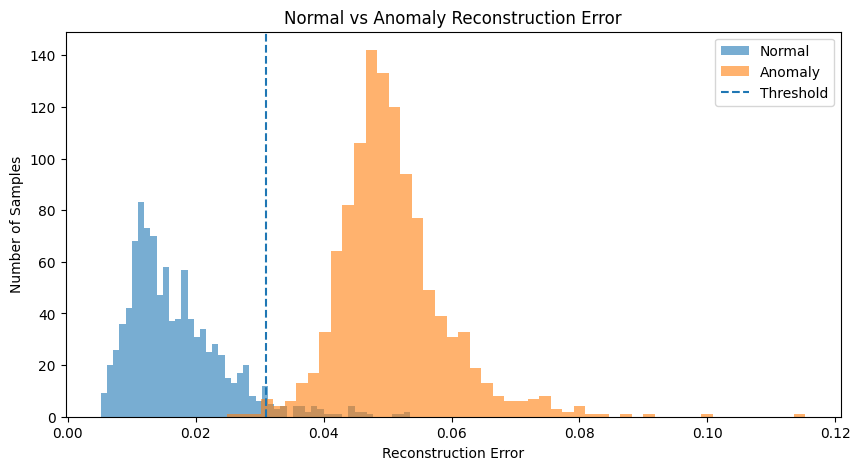

In [21]:
# 19. Plot Reconstruction Error
plt.figure(figsize=(10, 5))
plt.hist(
    normal_errors,
    bins=50,
    alpha=0.6,
    label="Normal"
)
plt.hist(
    anomaly_errors,
    bins=50,
    alpha=0.6,
    label="Anomaly"
)
plt.axvline(
    threshold,
    linestyle="--",
    label="Threshold"
)
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Samples")
plt.title(
    "Normal vs Anomaly Reconstruction Error"
)
plt.legend()
plt.show()

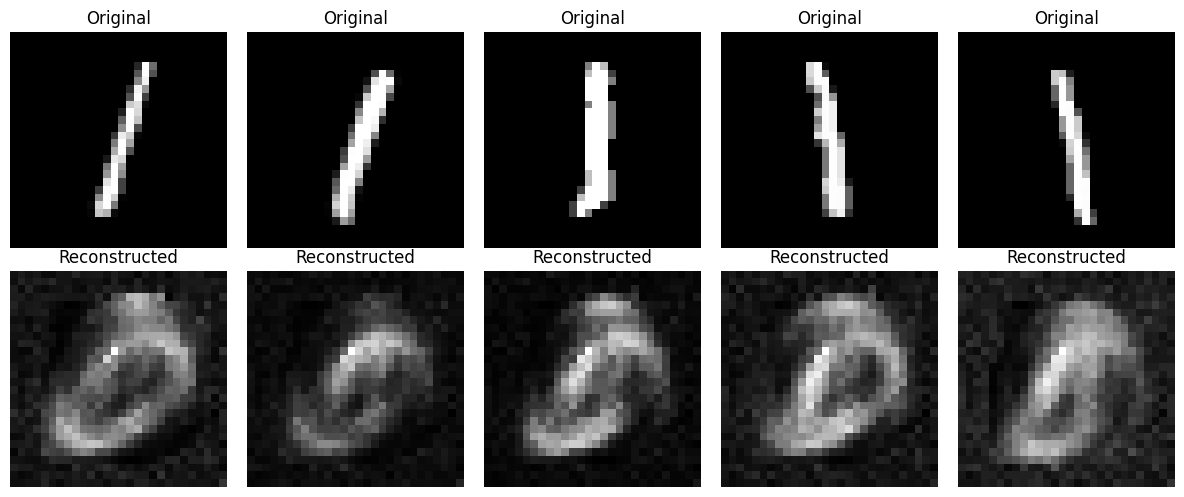

In [22]:
# 20. Display Anomaly Images
n = 5
plt.figure(figsize=(12, 5))
for i in range(n):
    # Original image
    plt.subplot(2, n, i + 1)
    plt.imshow(
        x_test_anomaly[i].reshape(28, 28),
        cmap="gray"
    )
    plt.title("Original")
    plt.axis("off")
    # Reconstructed image
    plt.subplot(2, n, i + 1 + n)
    plt.imshow(
        anomaly_reconstructed[i].reshape(28, 28),
        cmap="gray"
    )
    plt.title("Reconstructed")
    plt.axis("off")
plt.tight_layout()
plt.show()